<a href="https://colab.research.google.com/github/tejasarulmani/Retail-Inventory-Optimization/blob/main/Retail_Inventory_Optimization_EOQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("marian447/retail-store-sales-transactions")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'retail-store-sales-transactions' dataset.
Path to dataset files: /kaggle/input/retail-store-sales-transactions


In [12]:
import pandas as pd
import os

# The 'path' variable from the previous cell contains the directory of the downloaded dataset.
# We determined earlier that 'scanner_data.csv' is the correct file.
data_file = os.path.join(path, 'scanner_data.csv')

# Load the CSV into a pandas DataFrame
df = pd.read_csv(data_file)

# Display the first 5 rows of the DataFrame
print("First 5 rows of the DataFrame:")
display(df.head())

# Print the DataFrame's information
print("\nDataFrame Information:")
df.info()

First 5 rows of the DataFrame:


,Unnamed: 0,Date,Customer_ID,Transaction_ID,SKU_Category,SKU,Quantity,Sales_Amount
0,1,02/01/2016,2547,1,X52,0EM7L,1.0,3.13
1,2,02/01/2016,822,2,2ML,68BRQ,1.0,5.46
2,3,02/01/2016,3686,3,0H2,CZUZX,1.0,6.35
3,4,02/01/2016,3719,4,0H2,549KK,1.0,5.59
4,5,02/01/2016,9200,5,0H2,K8EHH,1.0,6.88



DataFrame Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131706 entries, 0 to 131705
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Unnamed: 0      131706 non-null  int64  
 1   Date            131706 non-null  object 
 2   Customer_ID     131706 non-null  int64  
 3   Transaction_ID  131706 non-null  int64  
 4   SKU_Category    131706 non-null  object 
 5   SKU             131706 non-null  object 
 6   Quantity        131706 non-null  float64
 7   Sales_Amount    131706 non-null  float64
dtypes: float64(2), int64(3), object(3)
memory usage: 8.0+ MB


In [13]:
# Rename columns to simpler names
df = df.rename(columns={
    'Unnamed: 0': 'Index',
    'Date': 'Date',
    'Customer_ID': 'Customer_ID',
    'Transaction_ID': 'Transaction_ID',
    'SKU_Category': 'Category_ID',
    'SKU': 'SKU_ID',
    'Quantity': 'Quantity',
    'Sales_Amount': 'Sales_Amount'
})

# Convert the 'Date' column to standard pandas datetime format, specifying dayfirst=True
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Create a new column called 'Unit_Price' by dividing Sales_Amount by Quantity
# Handle potential division by zero if Quantity can be 0 or NaN
df['Unit_Price'] = df['Sales_Amount'] / df['Quantity']

# Display the first 3 rows of the updated DataFrame
print("First 3 rows of the DataFrame after transformations:")
display(df.head(3))

First 3 rows of the DataFrame after transformations:


,Index,Date,Customer_ID,Transaction_ID,Category_ID,SKU_ID,Quantity,Sales_Amount,Unit_Price
0,1,2016-01-02,2547,1,X52,0EM7L,1.0,3.13,3.13
1,2,2016-01-02,822,2,2ML,68BRQ,1.0,5.46,5.46
2,3,2016-01-02,3686,3,0H2,CZUZX,1.0,6.35,6.35


In [14]:
# Group by SKU_ID and calculate total sales, then sort in descending order
sku_sales = df.groupby('SKU_ID')['Sales_Amount'].sum().sort_values(ascending=False).reset_index()

# Calculate the cumulative sum of sales
sku_sales['Cumulative_Sales'] = sku_sales['Sales_Amount'].cumsum()

# Calculate the cumulative percentage of total sales
sku_sales['Cumulative_Percentage'] = sku_sales['Cumulative_Sales'] / sku_sales['Sales_Amount'].sum()

# Filter for SKUs that make up the top 80% of sales
pareto_skus_df = sku_sales[sku_sales['Cumulative_Percentage'] <= 0.80]
pareto_skus = pareto_skus_df['SKU_ID'].tolist()

# Print the total number of SKUs and the number of SKUs in the 80% list
total_skus = df['SKU_ID'].nunique()
num_pareto_skus = len(pareto_skus)

print(f"Total number of unique SKUs: {total_skus}")
print(f"Number of SKUs making up the top 80% of sales: {num_pareto_skus}")

# Display the top SKU sales with cumulative percentages
print("\nSKU Sales with Cumulative Percentages (first 10 rows):")
display(sku_sales.head(10))

Total number of unique SKUs: 5242
Number of SKUs making up the top 80% of sales: 1136

SKU Sales with Cumulative Percentages (first 10 rows):


,SKU_ID,Sales_Amount,Cumulative_Sales,Cumulative_Percentage
0,3YDVF,29419.35,29419.35,0.018643
1,LJ26I,13571.45,42990.80,0.027243
2,IRQZ4,11681.63,54672.43,0.034646
3,DWJC4,10592.09,65264.52,0.041358
4,44RUE,8942.63,74207.15,0.047025
5,W6RZ8,8561.70,82768.85,0.052450
6,B87MU,8183.89,90952.74,0.057637
7,MYDIB,7933.95,98886.69,0.062664
8,BW8YX,7822.52,106709.21,0.067621
9,P35XJ,7759.64,114468.85,0.072539


In [15]:
df_top = df[df['SKU_ID'].isin(pareto_skus)]

print(f"Original DataFrame shape: {df.shape}")
print(f"Filtered DataFrame (df_top) shape: {df_top.shape}")
display(df_top.head())

Original DataFrame shape: (131706, 9)
Filtered DataFrame (df_top) shape: (92498, 9)


,Index,Date,Customer_ID,Transaction_ID,Category_ID,SKU_ID,Quantity,Sales_Amount,Unit_Price
1,2,2016-01-02,822,2,2ML,68BRQ,1.0,5.46,5.46
2,3,2016-01-02,3686,3,0H2,CZUZX,1.0,6.35,6.35
3,4,2016-01-02,3719,4,0H2,549KK,1.0,5.59,5.59
4,5,2016-01-02,9200,5,0H2,K8EHH,1.0,6.88,6.88
6,7,2016-01-02,1666,7,XG4,AHAE7,1.0,3.65,3.65


In [16]:
# Group df_top by SKU_ID and Date to find daily demand per item
daily_demand = df_top.groupby(['SKU_ID', 'Date'])['Quantity'].sum().reset_index()

# Group the daily demand data by SKU_ID to calculate EOQ inputs
eoq_inputs = daily_demand.groupby('SKU_ID')['Quantity'].agg(
    Annual_Demand=('sum'),
    Average_Daily_Demand=('mean'),
    Daily_Std_Dev=('std')
).reset_index()

# Display the first few rows of the eoq_inputs DataFrame
print("EOQ Inputs (first 5 rows):")
display(eoq_inputs.head())

EOQ Inputs (first 5 rows):


,SKU_ID,Annual_Demand,Average_Daily_Demand,Daily_Std_Dev
0,01L05,10.0,1.666667,0.516398
1,01V7M,45.0,1.125000,0.334932
2,07GHA,37.0,1.088235,0.378806
3,08F28,65.0,1.911765,0.865768
4,096VW,59.0,1.255319,0.487589


In [17]:
# Calculate the mean Unit_Price for each SKU_ID from df_top
avg_unit_price = df_top.groupby('SKU_ID')['Unit_Price'].mean().reset_index()
avg_unit_price.rename(columns={'Unit_Price': 'Average_Unit_Price'}, inplace=True)

# Merge the average unit price into the eoq_inputs DataFrame
eoq_inputs = pd.merge(eoq_inputs, avg_unit_price, on='SKU_ID', how='left')

# Add constant columns for EOQ parameters
eoq_inputs['Order_Cost'] = 50
eoq_inputs['Holding_Cost_Pct'] = 0.20
eoq_inputs['Lead_Time_Days'] = 14
eoq_inputs['Z_Score'] = 1.65 # Corresponds to a 95% service level for safety stock

print("EOQ Inputs DataFrame with pricing and business parameters (first 5 rows):")
display(eoq_inputs.head())

EOQ Inputs DataFrame with pricing and business parameters (first 5 rows):


,SKU_ID,Annual_Demand,Average_Daily_Demand,Daily_Std_Dev,Average_Unit_Price,Order_Cost,Holding_Cost_Pct,Lead_Time_Days,Z_Score
0,01L05,10.0,1.666667,0.516398,83.820000,50,0.2,14,1.65
1,01V7M,45.0,1.125000,0.334932,8.174186,50,0.2,14,1.65
2,07GHA,37.0,1.088235,0.378806,10.805143,50,0.2,14,1.65
3,08F28,65.0,1.911765,0.865768,9.583524,50,0.2,14,1.65
4,096VW,59.0,1.255319,0.487589,6.071176,50,0.2,14,1.65


In [18]:
import numpy as np

# Calculate Holding_Cost_Per_Unit
eoq_inputs['Holding_Cost_Per_Unit'] = eoq_inputs['Average_Unit_Price'] * eoq_inputs['Holding_Cost_Pct']

# Calculate EOQ
# Handle potential division by zero if Holding_Cost_Per_Unit is 0
eoq_inputs['EOQ'] = np.sqrt(
    (2 * eoq_inputs['Annual_Demand'] * eoq_inputs['Order_Cost']) /
    eoq_inputs['Holding_Cost_Per_Unit'].replace(0, np.nan) # Replace 0 with NaN to avoid division by zero
)

# Calculate Safety_Stock
# Handle potential NaN values from Daily_Std_Dev
eoq_inputs['Safety_Stock'] = (eoq_inputs['Z_Score'] * eoq_inputs['Daily_Std_Dev'] * np.sqrt(eoq_inputs['Lead_Time_Days']))

# Calculate Reorder_Point
eoq_inputs['Reorder_Point'] = (eoq_inputs['Average_Daily_Demand'] * eoq_inputs['Lead_Time_Days']) + eoq_inputs['Safety_Stock']

# Round EOQ, Safety_Stock, and Reorder_Point to the nearest whole number
eoq_inputs['EOQ'] = eoq_inputs['EOQ'].round().astype(pd.Int64Dtype())
eoq_inputs['Safety_Stock'] = eoq_inputs['Safety_Stock'].round().astype(pd.Int64Dtype())
eoq_inputs['Reorder_Point'] = eoq_inputs['Reorder_Point'].round().astype(pd.Int64Dtype())

print("EOQ Inputs DataFrame with calculated EOQ, Safety Stock, and Reorder Point (first 5 rows):")
display(eoq_inputs.head())

EOQ Inputs DataFrame with calculated EOQ, Safety Stock, and Reorder Point (first 5 rows):


,SKU_ID,Annual_Demand,Average_Daily_Demand,Daily_Std_Dev,Average_Unit_Price,Order_Cost,Holding_Cost_Pct,Lead_Time_Days,Z_Score,Holding_Cost_Per_Unit,EOQ,Safety_Stock,Reorder_Point
0,01L05,10.0,1.666667,0.516398,83.820000,50,0.2,14,1.65,16.764000,8,3,27
1,01V7M,45.0,1.125000,0.334932,8.174186,50,0.2,14,1.65,1.634837,52,2,18
2,07GHA,37.0,1.088235,0.378806,10.805143,50,0.2,14,1.65,2.161029,41,2,18
3,08F28,65.0,1.911765,0.865768,9.583524,50,0.2,14,1.65,1.916705,58,5,32
4,096VW,59.0,1.255319,0.487589,6.071176,50,0.2,14,1.65,1.214235,70,3,21


In [19]:
import numpy as np
import pandas as pd
import kagglehub
import os

# --- Re-create necessary upstream DataFrames and variables if kernel was reset ---

# From cell 4K0kAL30bshX: Download dataset and get path
path = kagglehub.dataset_download("marian447/retail-store-sales-transactions")

# From cell 46aWNS6RjJJ0: Load data into df
data_file = os.path.join(path, 'scanner_data.csv')
df = pd.read_csv(data_file)

# From cell cec85891: Rename columns, convert Date, calculate Unit_Price
df = df.rename(columns={
    'Unnamed: 0': 'Index',
    'Date': 'Date',
    'Customer_ID': 'Customer_ID',
    'Transaction_ID': 'Transaction_ID',
    'SKU_Category': 'Category_ID',
    'SKU': 'SKU_ID',
    'Quantity': 'Quantity',
    'Sales_Amount': 'Sales_Amount'
})
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df['Unit_Price'] = df['Sales_Amount'] / df['Quantity']

# From cell 119da9d6: Calculate Pareto SKUs
sku_sales = df.groupby('SKU_ID')['Sales_Amount'].sum().sort_values(ascending=False).reset_index()
sku_sales['Cumulative_Sales'] = sku_sales['Sales_Amount'].cumsum()
sku_sales['Cumulative_Percentage'] = sku_sales['Cumulative_Sales'] / sku_sales['Sales_Amount'].sum()
pareto_skus_df = sku_sales[sku_sales['Cumulative_Percentage'] <= 0.80]
pareto_skus = pareto_skus_df['SKU_ID'].tolist()

# From cell 5b20be0f: Filter original DataFrame to df_top
df_top = df[df['SKU_ID'].isin(pareto_skus)]

# From cell e87ebcf8: Create initial eoq_inputs DataFrame
daily_demand = df_top.groupby(['SKU_ID', 'Date'])['Quantity'].sum().reset_index()
eoq_inputs = daily_demand.groupby('SKU_ID')['Quantity'].agg(
    Annual_Demand=('sum'),
    Average_Daily_Demand=('mean'),
    Daily_Std_Dev=('std')
).reset_index()

# From cell 53db7a4f: Merge average unit price and add constant parameters
avg_unit_price = df_top.groupby('SKU_ID')['Unit_Price'].mean().reset_index()
avg_unit_price.rename(columns={'Unit_Price': 'Average_Unit_Price'}, inplace=True)
eoq_inputs = pd.merge(eoq_inputs, avg_unit_price, on='SKU_ID', how='left')
eoq_inputs['Order_Cost'] = 50
eoq_inputs['Holding_Cost_Pct'] = 0.20
eoq_inputs['Lead_Time_Days'] = 14
eoq_inputs['Z_Score'] = 1.65 # Corresponds to a 95% service level for safety stock

# From cell 1b319629: Calculate Holding_Cost_Per_Unit, EOQ, Safety_Stock, and Reorder_Point
eoq_inputs['Holding_Cost_Per_Unit'] = eoq_inputs['Average_Unit_Price'] * eoq_inputs['Holding_Cost_Pct']
eoq_inputs['EOQ'] = np.sqrt(
    (2 * eoq_inputs['Annual_Demand'] * eoq_inputs['Order_Cost']) /
    eoq_inputs['Holding_Cost_Per_Unit'].replace(0, np.nan)
)
eoq_inputs['Safety_Stock'] = (eoq_inputs['Z_Score'] * eoq_inputs['Daily_Std_Dev'] * np.sqrt(eoq_inputs['Lead_Time_Days']))
eoq_inputs['Reorder_Point'] = (eoq_inputs['Average_Daily_Demand'] * eoq_inputs['Lead_Time_Days']) + eoq_inputs['Safety_Stock']
eoq_inputs['EOQ'] = eoq_inputs['EOQ'].round().astype(pd.Int64Dtype())
eoq_inputs['Safety_Stock'] = eoq_inputs['Safety_Stock'].round().astype(pd.Int64Dtype())
eoq_inputs['Reorder_Point'] = eoq_inputs['Reorder_Point'].round().astype(pd.Int64Dtype())

# --- Original code for operational and financial calculations starts here ---

# Current state (assuming 12 orders per year initially)
eoq_inputs['Current_Orders_Per_Year'] = 12.0
eoq_inputs['Current_Order_Cycle_Days'] = 365 / 12
eoq_inputs['Current_Order_Quantity'] = eoq_inputs['Annual_Demand'] / eoq_inputs['Current_Orders_Per_Year']

# EOQ-based state
eoq_inputs['EOQ_Orders_Per_Year'] = eoq_inputs['Annual_Demand'] / eoq_inputs['EOQ'].replace(0, np.nan)
eoq_inputs['EOQ_Orders_Per_Year'] = eoq_inputs['EOQ_Orders_Per_Year'].fillna(0)

eoq_inputs['EOQ_Order_Cycle_Days'] = 365 / eoq_inputs['EOQ_Orders_Per_Year'].replace(0, np.nan)
eoq_inputs['EOQ_Order_Cycle_Days'] = eoq_inputs['EOQ_Order_Cycle_Days'].fillna(0)

# --- Financial Calculations ---

# Calculate Total_Current_Cost
current_ordering_cost = eoq_inputs['Current_Orders_Per_Year'] * eoq_inputs['Order_Cost']
current_holding_cost = (eoq_inputs['Current_Order_Quantity'] / 2) * eoq_inputs['Holding_Cost_Per_Unit']
eoq_inputs['Total_Current_Cost'] = current_ordering_cost + current_holding_cost

# Calculate Total_EOQ_Cost
eoq_ordering_cost = eoq_inputs['EOQ_Orders_Per_Year'] * eoq_inputs['Order_Cost']
eoq_holding_cost = (eoq_inputs['EOQ'].replace(pd.NA, np.nan).fillna(0) / 2) * eoq_inputs['Holding_Cost_Per_Unit']
eoq_inputs['Total_EOQ_Cost'] = eoq_ordering_cost + eoq_holding_cost

# Calculate Cost_Savings
eoq_inputs['Cost_Savings'] = eoq_inputs['Total_Current_Cost'] - eoq_inputs['Total_EOQ_Cost']

# Calculate Savings_Percentage
eoq_inputs['Savings_Percentage'] = (eoq_inputs['Cost_Savings'] / eoq_inputs['Total_Current_Cost'].replace(0, np.nan)) * 100
eoq_inputs['Savings_Percentage'] = eoq_inputs['Savings_Percentage'].fillna(0)

# Display SKUs with relevant operational and financial metrics
print("SKUs with Operational and Financial Metrics (first 5 rows):")
display(eoq_inputs[[
    'SKU_ID',
    'Annual_Demand',
    'Current_Orders_Per_Year',
    'Current_Order_Cycle_Days',
    'Current_Order_Quantity',
    'EOQ',
    'EOQ_Orders_Per_Year',
    'EOQ_Order_Cycle_Days',
    'Total_Current_Cost',
    'Total_EOQ_Cost',
    'Cost_Savings',
    'Savings_Percentage'
]].head())

Using Colab cache for faster access to the 'retail-store-sales-transactions' dataset.
SKUs with Operational and Financial Metrics (first 5 rows):


,SKU_ID,Annual_Demand,Current_Orders_Per_Year,Current_Order_Cycle_Days,Current_Order_Quantity,EOQ,EOQ_Orders_Per_Year,EOQ_Order_Cycle_Days,Total_Current_Cost,Total_EOQ_Cost,Cost_Savings,Savings_Percentage
0,01L05,10.0,12.0,30.416667,0.833333,8,1.25,292.0,606.985000,129.556,477.429,78.655815
1,01V7M,45.0,12.0,30.416667,3.750000,52,0.865385,421.777778,603.065320,85.774998,517.290322,85.776831
2,07GHA,37.0,12.0,30.416667,3.083333,41,0.902439,404.459459,603.331586,89.423037,513.908549,85.178459
3,08F28,65.0,12.0,30.416667,5.416667,58,1.12069,325.692308,605.191075,111.618921,493.572155,81.556417
4,096VW,59.0,12.0,30.416667,4.916667,70,0.842857,433.050847,602.984995,84.641092,518.343903,85.962985


In [22]:
# Sort eoq_inputs by 'Cost_Savings' descending and take the top 10 rows
executive_summary_df = eoq_inputs.sort_values(by='Cost_Savings', ascending=False).head(10)

# Select the specified columns for the executive summary
executive_summary_df = executive_summary_df[[
    'SKU_ID',
    'EOQ',
    'Reorder_Point',
    'Current_Orders_Per_Year',
    'EOQ_Orders_Per_Year',
    'EOQ_Order_Cycle_Days',
    'Total_Current_Cost',
    'Total_EOQ_Cost',
    'Cost_Savings',
    'Savings_Percentage'
]]

# Define a styling function to format currency and percentage
def format_executive_summary(df):
    return df.style \
        .background_gradient(cmap='Greens', subset=['Cost_Savings', 'Savings_Percentage']) \
        .format({
            'Current_Orders_Per_Year': '{:.0f}',
            'EOQ_Orders_Per_Year': '{:.2f}',
            'EOQ_Order_Cycle_Days': '{:.0f} days',
            'Total_Current_Cost': '${:,.2f}',
            'Total_EOQ_Cost': '${:,.2f}',
            'Cost_Savings': '${:,.2f}',
            'Savings_Percentage': '{:.1f}%'
        }) \
        .hide(axis="index")

# Apply the styling and display the dataframe
print("Executive Summary: Top 10 SKUs by Cost Savings")
display(format_executive_summary(executive_summary_df))

Executive Summary: Top 10 SKUs by Cost Savings


SKU_ID,EOQ,Reorder_Point,Current_Orders_Per_Year,EOQ_Orders_Per_Year,EOQ_Order_Cycle_Days,Total_Current_Cost,Total_EOQ_Cost,Cost_Savings,Savings_Percentage
N25TU,29,14,12,0.79,460 days,$602.55,$78.21,$524.33,87.0%
DYMFI,165,37,12,0.78,467 days,$602.55,$78.22,$524.33,87.0%
1CJ28,132,41,12,0.78,468 days,$602.55,$78.23,$524.32,87.0%
YS9IS,50,15,12,0.78,468 days,$602.55,$78.25,$524.30,87.0%
YR1OH,31,16,12,0.77,471 days,$602.56,$78.37,$524.19,87.0%
0POSZ,10,14,12,0.80,456 days,$602.56,$78.38,$524.18,87.0%
DE1MW,18,14,12,0.78,469 days,$602.56,$78.40,$524.16,87.0%
H8P2L,1426,768,12,0.78,466 days,$602.56,$78.41,$524.16,87.0%
Q2G19,18,17,12,0.78,469 days,$602.56,$78.41,$524.15,87.0%
9I5KY,50,25,12,0.78,468 days,$602.56,$78.46,$524.11,87.0%


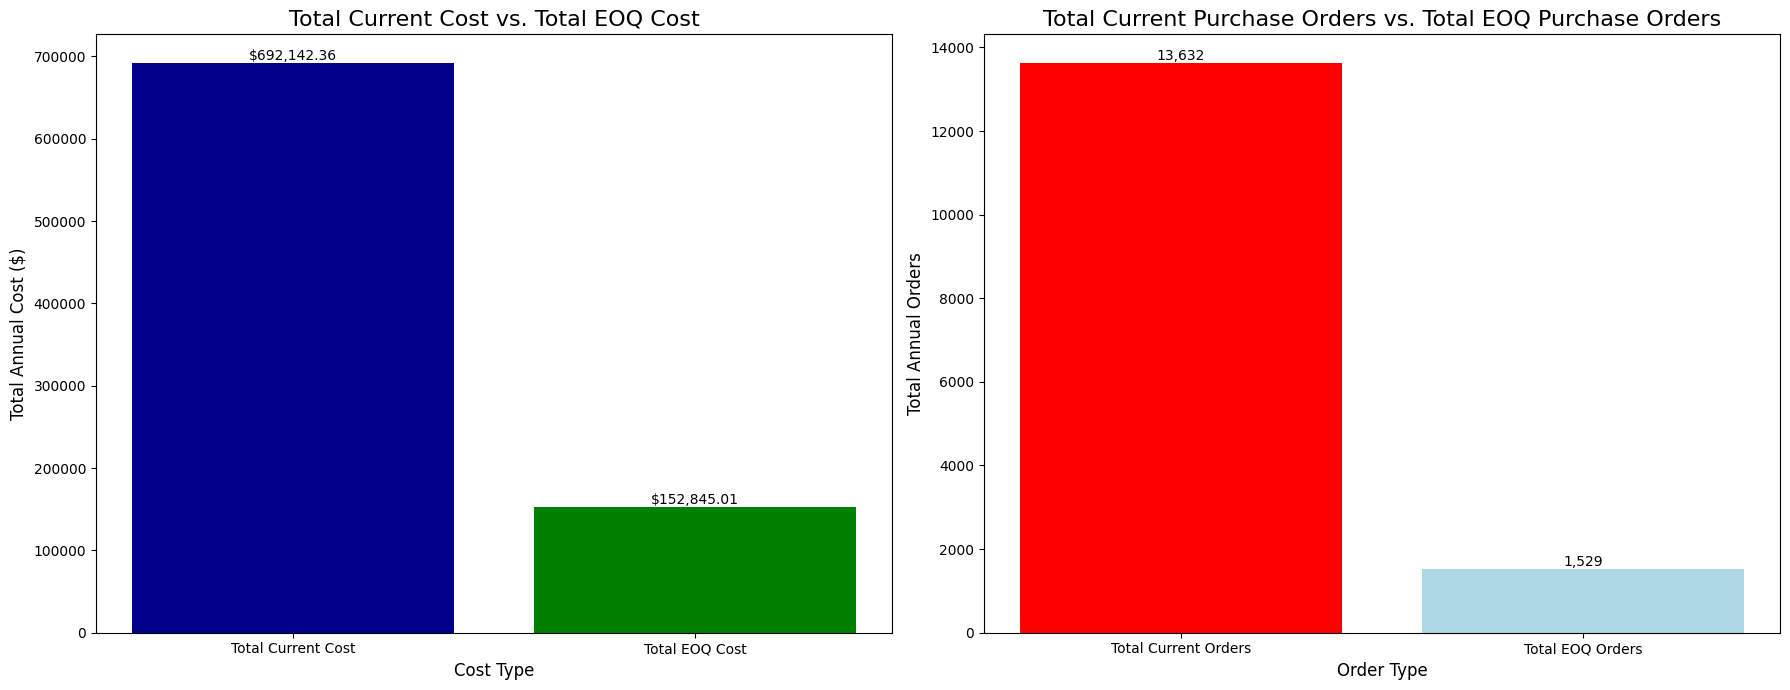


--- Executive Summary of EOQ Optimization Impact ---
Total Projected Annual Cost Savings: $539,297.35
Total Annual Purchase Orders Eliminated: 12,103


In [23]:
import matplotlib.pyplot as plt
import pandas as pd

# Calculate the grand totals from the full eoq_inputs DataFrame
grand_total_current_cost = eoq_inputs['Total_Current_Cost'].sum()
grand_total_eoq_cost = eoq_inputs['Total_EOQ_Cost'].sum()
grand_total_cost_savings = grand_total_current_cost - grand_total_eoq_cost
grand_total_current_orders = eoq_inputs['Current_Orders_Per_Year'].sum()
grand_total_eoq_orders = eoq_inputs['EOQ_Orders_Per_Year'].sum()
grand_total_orders_eliminated = grand_total_current_orders - grand_total_eoq_orders

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# --- First Chart: Cost Comparison ---

cost_data = pd.DataFrame({
    'Cost Type': ['Total Current Cost', 'Total EOQ Cost'],
    'Amount': [grand_total_current_cost, grand_total_eoq_cost]
})
colors_cost = ['darkblue', 'green']

axes[0].bar(cost_data['Cost Type'], cost_data['Amount'], color=colors_cost)
axes[0].set_title('Total Current Cost vs. Total EOQ Cost', fontsize=16)
axes[0].set_xlabel('Cost Type', fontsize=12)
axes[0].set_ylabel('Total Annual Cost ($)', fontsize=12)

# Add exact dollar amounts on top of each bar for the cost chart
for p in axes[0].patches:
    axes[0].annotate(f'${p.get_height():,.2f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

# --- Second Chart: Order Comparison ---

order_data = pd.DataFrame({
    'Order Type': ['Total Current Orders', 'Total EOQ Orders'],
    'Count': [grand_total_current_orders, grand_total_eoq_orders]
})
colors_orders = ['red', 'lightblue']

axes[1].bar(order_data['Order Type'], order_data['Count'], color=colors_orders)
axes[1].set_title('Total Current Purchase Orders vs. Total EOQ Purchase Orders', fontsize=16)
axes[1].set_xlabel('Order Type', fontsize=12)
axes[1].set_ylabel('Total Annual Orders', fontsize=12)

# Add exact integer values on top of each bar for the orders chart
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

# --- Executive Summary Statement ---
print("\n--- Executive Summary of EOQ Optimization Impact ---")
print(f"Total Projected Annual Cost Savings: ${grand_total_cost_savings:,.2f}")
print(f"Total Annual Purchase Orders Eliminated: {grand_total_orders_eliminated:,.0f}")